<div align="center">

# UNIVERSIDAD AUTÓNOMA DEL ESTADO DE MÉXICO

---

## Investigación de Operaciones

### Ejercicio 3: Ruta más corta entre los nodos 1 y 9

<br>

**Docente:** Hazem Álvarez Rodríguez

**Alumno:** Sergio Manuel Martínez Cortés

*Fecha de entrega:* 25 de noviembre de 2026

</div>

---

## Objetivos

- **General:** determinar la ruta de menor costo del nodo 1 al nodo 9.
- **Específicos:**
  1. Representar la red dirigida con sus costos.
  2. Resolver el problema con el algoritmo de Dijkstra.
  3. Formular y resolver el modelo de programación lineal con Gran M.
  4. Comparar ambos métodos e identificar la ruta crítica.

In [1]:
# ------------------------------------------------------------------
# CONFIGURACIÓN DEL ENTORNO
# ------------------------------------------------------------------
import heapq
import math
import numbers
import re
from dataclasses import dataclass
from fractions import Fraction

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import Math, display
from matplotlib.lines import Line2D

# Paleta única: la comparten las tablas y todas las gráficas.
PALETA = {
    "nodo":         "#4F5D75",   # nodos intermedios (azul pizarra)
    "origen":       "#2A9D8F",   # nodo origen (verde azulado)
    "destino":      "#E07A5F",   # nodo destino (terracota)
    "arco":         "#7C8798",   # arcos de la red
    "arco_tenue":   "#D3D8E0",   # arcos que no pertenecen a la ruta resaltada
    "ruta":         "#E8890C",   # ruta crítica (ámbar)
    "texto":        "#2B2D42",
    "encabezado":   "#4F5D75",
    "fila_alterna": "#EEF1F6",
}

# Estilo de las gráficas: tipografía serif con aire de documento LaTeX.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
    "axes.titlesize": 14,
    "figure.dpi": 110,
    "figure.facecolor": "white",
})
try:                                    # gráficas nítidas en pantalla y PDF
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats("retina")
except ImportError:
    pass


# ------------------------------------------------------------------
# UTILIDADES DE PRESENTACIÓN
# ------------------------------------------------------------------
_ESCAPES_TEX = str.maketrans({
    "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_",
    "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}",
    "^": r"\textasciicircum{}", "\\": r"\textbackslash{}",
})


def _fmt(valor):
    """Formatea un valor de tabla: enteros sin decimales e infinito como ∞."""
    if isinstance(valor, numbers.Real) and not isinstance(valor, bool):
        if isinstance(valor, float) and math.isinf(valor):
            return "∞"
        return str(int(valor)) if valor == int(valor) else str(valor)
    return str(valor)


def _tex(texto):
    """Escapa texto para LaTeX y convierte los símbolos →, ∞ y d(n)."""
    t = str(texto).translate(_ESCAPES_TEX)
    t = t.replace("→", r"$\rightarrow$").replace("∞", r"$\infty$")
    return re.sub(r"\bd\((\d)\)", r"$d(\1)$", t)


class Tabla:
    """DataFrame con dos representaciones:
    HTML con la paleta del ejercicio (notebook) y LaTeX/booktabs (PDF).
    `partir=2` coloca la tabla en dos bloques lado a lado para ahorrar espacio.
    """

    def __init__(self, df, titulo=None, partir=1):
        self.df, self.titulo, self.partir = df, titulo, partir

    def _datos(self):
        enc = [str(c) for c in self.df.columns]
        filas = [[_fmt(v) for v in fila]
                 for fila in self.df.itertuples(index=False, name=None)]
        alin = ["l" if max([len(f[k]) for f in filas] + [0]) > 14 else "c"
                for k in range(len(enc))]
        alto = math.ceil(len(filas) / self.partir)
        bloques = [filas[b * alto:(b + 1) * alto] for b in range(self.partir)]
        for bloque in bloques:                       # rellena el último bloque
            bloque.extend([[""] * len(enc)] * (alto - len(bloque)))
        return enc, bloques, alin, alto

    def _repr_html_(self):
        enc, bloques, alin, alto = self._datos()
        P = PALETA
        sep = '<td style="border:none;background:transparent;min-width:26px"></td>'
        celda = ('<{t} style="padding:5px 14px;text-align:{a};color:{c};'
                 'background:{bg};border-bottom:1px solid #D3D8E0">{v}</{t}>')
        cab = sep.join(
            "".join(celda.format(t="th", a="center", c="#FFFFFF",
                                 bg=P["encabezado"], v=e) for e in enc)
            for _ in bloques)
        cuerpo = ""
        for r in range(alto):
            bg = P["fila_alterna"] if r % 2 else "#FFFFFF"
            cuerpo += "<tr>" + sep.join(
                "".join(celda.format(t="td", a=a, c=P["texto"], bg=bg, v=v)
                        for v, a in zip(bloque[r], alin))
                for bloque in bloques) + "</tr>"
        titulo = (f'<caption style="caption-side:top;text-align:left;'
                  f'font-weight:600;padding:4px 0;color:{P["texto"]}">'
                  f'{self.titulo}</caption>') if self.titulo else ""
        return (f'<table style="border-collapse:collapse;margin:8px 0;'
                f'font-size:0.95em">{titulo}<tr>{cab}</tr>{cuerpo}</table>')

    def _repr_latex_(self):
        enc, bloques, alin, alto = self._datos()
        columnas = r"@{\hspace{2.5em}}".join("".join(alin) for _ in bloques)
        cab = " & ".join(rf"\textbf{{{_tex(e)}}}" for e in enc * self.partir)
        cuerpo = "\n".join(
            " & ".join(_tex(v) for bloque in bloques for v in bloque[r]) + r" \\"
            for r in range(alto))
        titulo = rf"\captionof{{table}}{{{_tex(self.titulo)}}}" if self.titulo else ""
        return (
            "\\begin{center}\n\\begin{minipage}{\\linewidth}\\centering\n"
            f"{titulo}\n\\vspace{{4pt}}\n{{\\small\n"
            f"\\begin{{tabular}}{{{columnas}}}\n\\toprule\n{cab} \\\\\n\\midrule\n"
            f"{cuerpo}\n\\bottomrule\n\\end{{tabular}}}}\n"
            "\\end{minipage}\n\\end{center}")

    def __repr__(self):
        return self.df.to_string(index=False)


def formato_ruta(ruta):
    """[1, 3, 5] -> '1 → 3 → 5'."""
    return " → ".join(map(str, ruta))


print("Entorno listo.")

Entorno listo.


## 1. Definición de la red

La red está formada por **9 nodos** y **20 arcos dirigidos**. Cada arco se declara como una terna `(origen, destino, costo)`; de ella se derivan el conjunto de nodos y el diccionario de costos que usan las demás secciones.

In [2]:
# Arcos dirigidos: (origen, destino, costo)
ARCOS = [
    (1, 2, 4), (1, 3, 2),
    (2, 3, 4), (3, 2, 2),
    (2, 4, 7), (3, 4, 9), (3, 5, 6),
    (5, 4, 2), (4, 6, 1), (4, 7, 5),
    (5, 6, 4), (5, 7, 3), (5, 8, 2),
    (7, 6, 4), (6, 7, 1),
    (6, 9, 5), (7, 9, 5),
    (8, 7, 2), (7, 8, 3), (8, 9, 6),
]
ORIGEN, DESTINO = 1, 9

NODOS = sorted({n for i, j, _ in ARCOS for n in (i, j)})
COSTO = {(i, j): c for i, j, c in ARCOS}

df_arcos = pd.DataFrame(ARCOS, columns=["Origen", "Destino", "Costo"])
print(f"Nodos: {len(NODOS)}   |   Arcos: {len(ARCOS)}")
display(Tabla(df_arcos, "Arcos dirigidos de la red y su costo", partir=2))

Nodos: 9   |   Arcos: 20


Origen,Destino,Costo,,Origen,Destino,Costo
1,2,4,,5,6,4
1,3,2,,5,7,3
2,3,4,,5,8,2
3,2,2,,7,6,4
2,4,7,,6,7,1
3,4,9,,6,9,5
3,5,6,,7,9,5
5,4,2,,8,7,2
4,6,1,,7,8,3
4,7,5,,8,9,6


## 2. Visualización de la red

Se construye un grafo dirigido con `networkx`. Los nodos tienen posiciones fijas para reproducir el esquema del ejercicio: el origen se pinta en verde azulado y el destino en terracota. Los pares de arcos opuestos (por ejemplo el 2 con el 3) se dibujan curvos para que no se encimen.

La función `dibujar_red` se reutiliza más adelante para resaltar la ruta crítica.

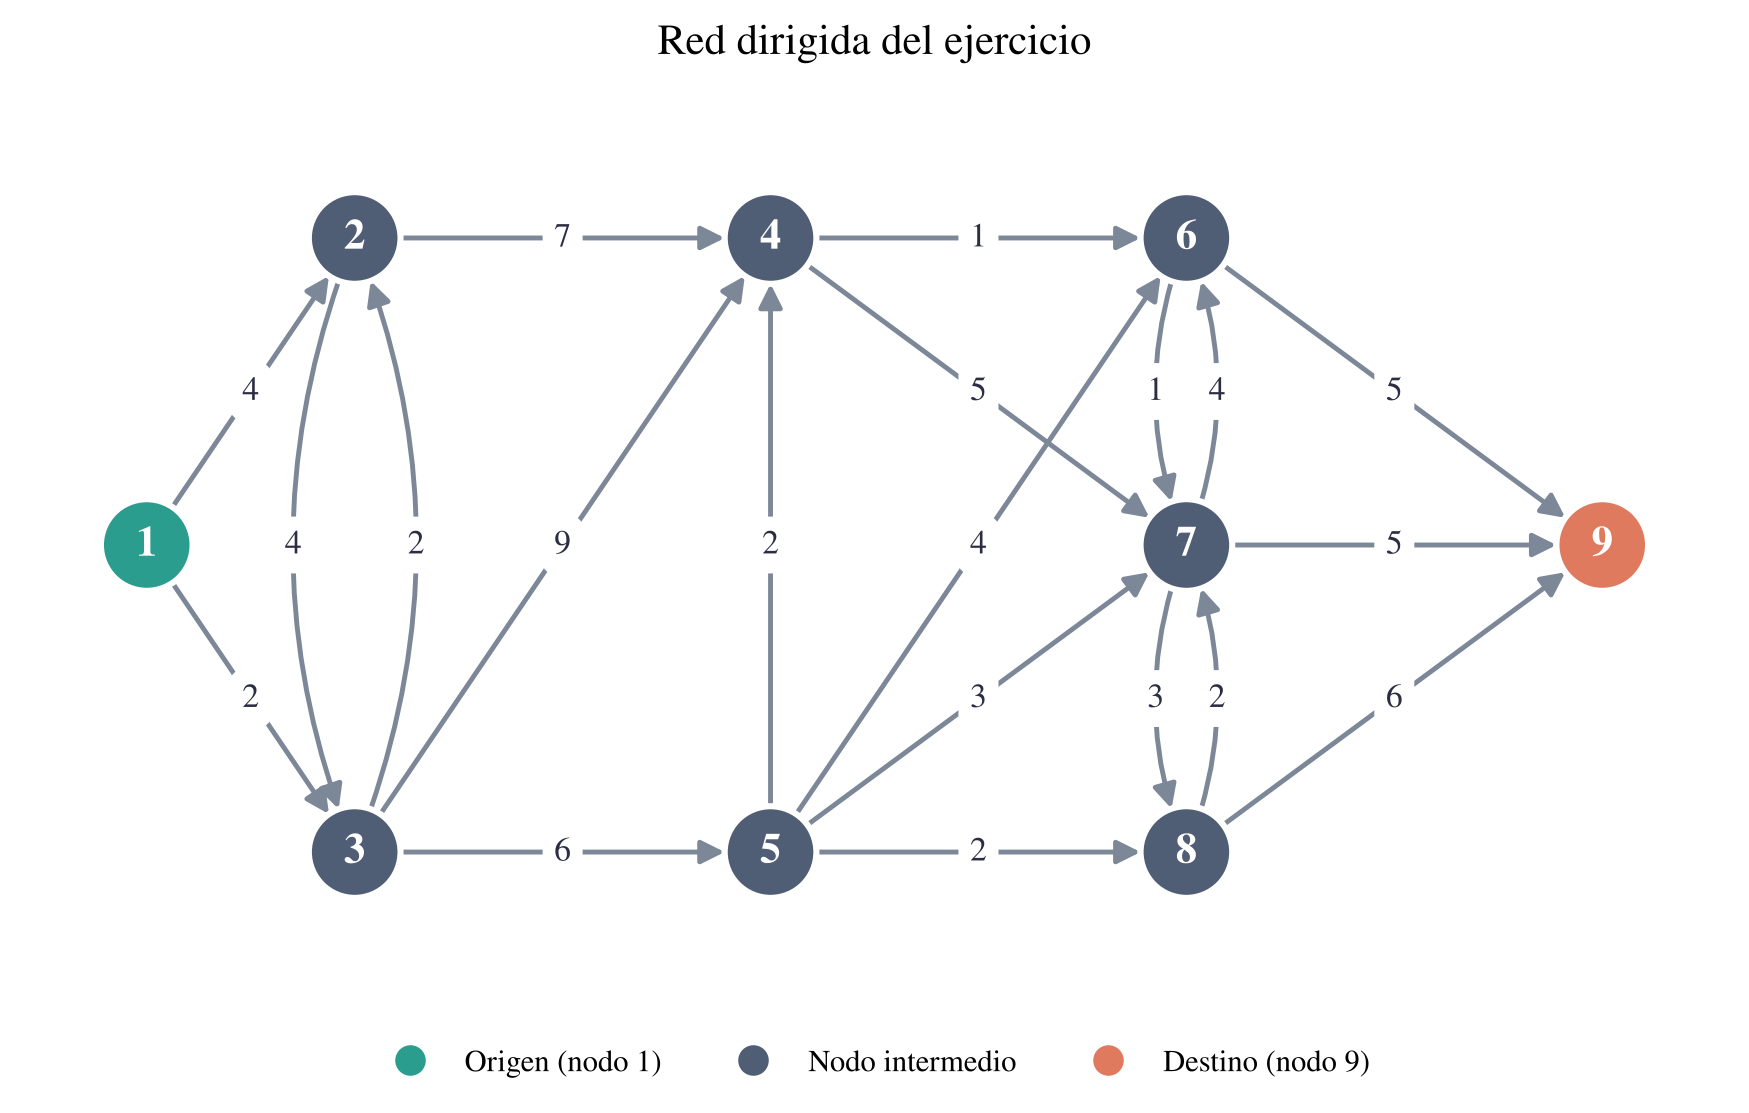

In [3]:
G = nx.DiGraph()
G.add_weighted_edges_from(ARCOS)

# Posiciones fijas (x, y) de cada nodo
POS = {
    1: (0, 1), 2: (1, 2), 3: (1, 0),
    4: (3, 2), 5: (3, 0),
    6: (5, 2), 7: (5, 1), 8: (5, 0),
    9: (7, 1),
}
TAM_NODO = 900


def dibujar_red(ruta=None, titulo=""):
    """Dibuja la red. Si se indica `ruta` (lista de nodos), resalta sus arcos."""
    arcos_ruta = set(zip(ruta, ruta[1:])) if ruta else set()
    opuestos = {e for e in G.edges if G.has_edge(e[1], e[0])}
    grupos = [([e for e in G.edges if e not in opuestos], "arc3,rad=0"),
              (sorted(opuestos), "arc3,rad=0.2")]

    fig, ax = plt.subplots(figsize=(10, 5.8))
    colores = [PALETA["origen"] if n == ORIGEN else
               PALETA["destino"] if n == DESTINO else PALETA["nodo"]
               for n in G.nodes]
    nx.draw_networkx_nodes(G, POS, ax=ax, node_size=TAM_NODO,
                           node_color=colores, edgecolors="white", linewidths=2)
    nx.draw_networkx_labels(G, POS, ax=ax, font_color="white", font_size=14,
                            font_weight="bold", font_family="serif")

    for aristas, estilo in grupos:
        normales = [e for e in aristas if e not in arcos_ruta]
        criticos = [e for e in aristas if e in arcos_ruta]
        color_base = PALETA["arco_tenue"] if ruta else PALETA["arco"]
        nx.draw_networkx_edges(G, POS, edgelist=normales, ax=ax,
                               edge_color=color_base, width=1.6, arrowsize=16,
                               node_size=TAM_NODO, connectionstyle=estilo)
        nx.draw_networkx_edges(G, POS, edgelist=criticos, ax=ax,
                               edge_color=PALETA["ruta"], width=3.4,
                               arrowsize=22, node_size=TAM_NODO,
                               connectionstyle=estilo)
        etiquetas = {e: COSTO[e] for e in aristas}
        try:                            # etiquetas sobre arcos curvos (networkx >= 3.2)
            nx.draw_networkx_edge_labels(G, POS, edge_labels=etiquetas, ax=ax,
                                         font_size=11, font_family="serif",
                                         font_color=PALETA["texto"], rotate=False,
                                         connectionstyle=estilo)
        except TypeError:
            nx.draw_networkx_edge_labels(G, POS, edge_labels=etiquetas, ax=ax,
                                         font_size=11, font_family="serif",
                                         font_color=PALETA["texto"])

    leyenda = [
        Line2D([], [], marker="o", ls="", ms=11, mfc=PALETA["origen"],
               mec="white", label=f"Origen (nodo {ORIGEN})"),
        Line2D([], [], marker="o", ls="", ms=11, mfc=PALETA["nodo"],
               mec="white", label="Nodo intermedio"),
        Line2D([], [], marker="o", ls="", ms=11, mfc=PALETA["destino"],
               mec="white", label=f"Destino (nodo {DESTINO})"),
    ]
    if ruta:
        leyenda.append(Line2D([], [], color=PALETA["ruta"], lw=3.4,
                              label="Ruta crítica"))
    ax.legend(handles=leyenda, loc="lower center", ncol=len(leyenda),
              frameon=False, bbox_to_anchor=(0.5, -0.04), fontsize=10)

    ax.set_title(titulo.replace("→", r"$\rightarrow$"), pad=10)
    ax.set_xlim(-0.6, 7.6)
    ax.set_ylim(-0.7, 2.5)
    ax.axis("off")
    plt.show()


dibujar_red(titulo="Red dirigida del ejercicio")

## 3. Método 1: Algoritmo de Dijkstra

Dijkstra encuentra la distancia mínima desde el origen a todos los nodos. Es válido porque **todos los costos son no negativos**. La función guarda un historial de iteraciones y **todos** los predecesores que alcanzan la distancia mínima, de modo que después se puedan reconstruir las rutas óptimas empatadas.

In [4]:
def dijkstra(arcos, origen, nodos):
    """Devuelve (distancias, predecesores, historial de iteraciones)."""
    adyacentes = {n: [] for n in nodos}
    for i, j, c in arcos:
        adyacentes[i].append((j, c))

    dist = {n: float("inf") for n in nodos}
    dist[origen] = 0
    pred = {n: [] for n in nodos}
    cola, fijados, historial = [(0, origen)], set(), []

    while cola:
        d_actual, nodo = heapq.heappop(cola)
        if nodo in fijados or d_actual != dist[nodo]:
            continue
        fijados.add(nodo)

        for vecino, costo in adyacentes[nodo]:
            nueva = d_actual + costo
            if nueva < dist[vecino]:
                dist[vecino] = nueva
                pred[vecino] = [nodo]
                heapq.heappush(cola, (nueva, vecino))
            elif nueva == dist[vecino]:          # empate: otra ruta óptima
                pred[vecino].append(nodo)

        historial.append({"Iteración": len(historial) + 1, "Nodo fijado": nodo,
                          **{f"d({n})": dist[n] for n in nodos}})
    return dist, pred, historial


dist, pred, historial = dijkstra(ARCOS, ORIGEN, NODOS)

print(f"Costo mínimo {ORIGEN} → {DESTINO}: {dist[DESTINO]}")
display(Tabla(pd.DataFrame(historial),
              "Iteraciones del algoritmo de Dijkstra (∞: nodo aún no alcanzado)"))

Costo mínimo 1 → 9: 16


Iteración,Nodo fijado,d(1),d(2),d(3),d(4),d(5),d(6),d(7),d(8),d(9)
1,1,0,4,2,∞,∞,∞,∞,∞,∞
2,3,0,4,2,11,8,∞,∞,∞,∞
3,2,0,4,2,11,8,∞,∞,∞,∞
4,5,0,4,2,10,8,12,11,10,∞
5,4,0,4,2,10,8,11,11,10,∞
6,8,0,4,2,10,8,11,11,10,16
7,6,0,4,2,10,8,11,11,10,16
8,7,0,4,2,10,8,11,11,10,16
9,9,0,4,2,10,8,11,11,10,16


### 3.1 Reconstrucción de rutas óptimas

Con los predecesores registrados se recuperan **todas** las rutas que alcanzan el costo mínimo (puede haber empates).

In [5]:
def reconstruir_rutas(pred, origen, nodo):
    """Todas las rutas óptimas desde `origen` hasta `nodo`."""
    if nodo == origen:
        return [[origen]]
    return [ruta + [nodo]
            for anterior in pred[nodo]
            for ruta in reconstruir_rutas(pred, origen, anterior)]


rutas_optimas = reconstruir_rutas(pred, ORIGEN, DESTINO)

print("Rutas óptimas encontradas:")
for ruta in rutas_optimas:
    print(f"   {formato_ruta(ruta)}   | costo = {dist[DESTINO]}")
print(f"\nTotal de rutas óptimas: {len(rutas_optimas)}")

Rutas óptimas encontradas:
   1 → 3 → 5 → 8 → 9   | costo = 16
   1 → 3 → 5 → 4 → 6 → 9   | costo = 16
   1 → 3 → 5 → 7 → 9   | costo = 16

Total de rutas óptimas: 3


## 4. Método 2: Programación lineal con Gran M

### 4.1 Formulación del modelo

- **Variables:** $x_{ij} = 1$ si se usa el arco $(i,j)$ y $0$ en caso contrario, con $x_{ij} \ge 0$.
- **Función objetivo:** minimizar $Z = \sum c_{ij}\, x_{ij}$.
- **Restricciones de conservación de flujo:**
  - Nodo 1: sale 1 unidad.
  - Nodo 9: entra 1 unidad.
  - Nodos intermedios: flujo entrante = flujo saliente.

Se resuelve con el **método simplex de la Gran M**, representando cada costo como un par $(\text{coef}_M,\ \text{constante})$ para no asignar un valor numérico a $M$. La celda siguiente genera el modelo completo a partir de la lista de arcos.

In [6]:
def modelo_latex(arcos, nodos, origen, destino):
    """Devuelve (función objetivo, restricciones) como expresiones LaTeX."""
    x = lambda i, j: f"x_{{{i}{j}}}"

    terminos = [(str(c) if c != 1 else "") + x(i, j) for i, j, c in arcos]
    lineas = [" + ".join(terminos[k:k + 5]) for k in range(0, len(terminos), 5)]
    objetivo = (r"\begin{gathered} \text{\textbf{Función objetivo}} \\[6pt] "
                r"\begin{aligned} \min Z &= " + r" \\ &\quad + ".join(lineas)
                + r" \end{aligned} \end{gathered}")

    filas = []
    for nodo in nodos:
        salen = [x(i, j) for i, j, _ in arcos if i == nodo]
        entran = [x(i, j) for i, j, _ in arcos if j == nodo]
        if nodo == destino:               # se escribe "entrantes = 1" (b >= 0)
            izquierda, derecha = " + ".join(entran), 1
        else:                             # salientes - entrantes
            izquierda = " + ".join(salen) + "".join(f" - {e}" for e in entran)
            derecha = 1 if nodo == origen else 0
        filas.append(rf"\text{{Nodo {nodo}:}} \quad & {izquierda} = {derecha}")
    restricciones = (r"\begin{gathered} \text{\textbf{Restricciones de conservación de flujo}}"
                     r" \quad \text{(salientes } - \text{ entrantes } = b\text{)} \\[6pt] "
                     r"\begin{aligned} " + r" \\ ".join(filas)
                     + r" \end{aligned} \end{gathered}")
    return objetivo, restricciones


objetivo, restricciones = modelo_latex(ARCOS, NODOS, ORIGEN, DESTINO)
display(Math(objetivo))
display(Math(restricciones))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 4.2 Construcción y resolución del tableau

Se agrega una **variable artificial** por restricción y se penaliza con $M$. La restricción del nodo 9 se escribe como *suma de arcos entrantes = 1* para que su lado derecho sea no negativo.

Reglas del simplex utilizadas: entra la variable no básica con costo reducido negativo de **menor índice**; sale la fila con la **razón mínima** (desempate por menor índice de la variable básica). Un costo reducido es negativo si lo es su coeficiente de $M$ o, en caso de ser cero, su constante.

In [7]:
@dataclass(frozen=True)
class CostoM:
    """Número de la forma  m·M + c  (M es un símbolo, no un valor numérico)."""
    m: Fraction = Fraction(0)     # coeficiente de M
    c: Fraction = Fraction(0)     # constante

    def __add__(self, otro):
        return CostoM(self.m + otro.m, self.c + otro.c)

    def __sub__(self, otro):
        return CostoM(self.m - otro.m, self.c - otro.c)

    def __mul__(self, k):
        return CostoM(self.m * k, self.c * k)

    @property
    def es_negativo(self):
        """M es arbitrariamente grande: decide primero el coeficiente de M."""
        return self.m < 0 or (self.m == 0 and self.c < 0)


def construir_modelo(arcos, nodos, origen, destino):
    """Matriz A (con artificiales), vector b y costos simbólicos."""
    n_x, n_r = len(arcos), len(nodos)
    fila = {nodo: k for k, nodo in enumerate(nodos)}

    A = [[Fraction(0)] * (n_x + n_r) for _ in nodos]
    b = [Fraction(0)] * n_r
    b[fila[origen]] = b[fila[destino]] = Fraction(1)

    for col, (i, j, _) in enumerate(arcos):
        for nodo in nodos:
            coef = (i == nodo) - (j == nodo)          # salientes - entrantes
            A[fila[nodo]][col] = Fraction(-coef if nodo == destino else coef)
    for k in range(n_r):                              # columnas artificiales
        A[k][n_x + k] = Fraction(1)

    costos = ([CostoM(c=Fraction(c)) for _, _, c in arcos]
              + [CostoM(m=Fraction(1))] * n_r)         # artificiales cuestan M
    return A, b, costos


def simplex_gran_m(A, b, costos, nombres):
    """Simplex de la Gran M. Devuelve (base, tableau, historial)."""
    m, n = len(A), len(A[0])
    tab = [A[k][:] + [b[k]] for k in range(m)]
    base = list(range(n - m, n))                      # base inicial: artificiales
    historial = []

    def combinar(col):                                # Σ c_B · columna
        z = CostoM()
        for k in range(m):
            z = z + costos[base[k]] * tab[k][col]
        return z

    while True:
        reducidos = [costos[j] - combinar(j) for j in range(n)]
        candidatas = [j for j, r in enumerate(reducidos) if r.es_negativo]
        if not candidatas:
            return base, tab, historial               # óptimo alcanzado
        entra = min(candidatas)

        razones = [(tab[k][-1] / tab[k][entra], base[k], k)
                   for k in range(m) if tab[k][entra] > 0]
        if not razones:
            raise ValueError("Modelo no acotado.")
        _, sale, k_pivote = min(razones, key=lambda t: (t[0], t[1]))

        pivote = tab[k_pivote][entra]                 # operación de pivoteo
        tab[k_pivote] = [v / pivote for v in tab[k_pivote]]
        for k in range(m):
            if k != k_pivote and tab[k][entra] != 0:
                factor = tab[k][entra]
                tab[k] = [v - factor * w for v, w in zip(tab[k], tab[k_pivote])]
        base[k_pivote] = entra

        z = combinar(n)                               # valor actual de Z
        historial.append({"Iteración": len(historial) + 1,
                          "Entra": nombres[entra], "Sale": nombres[sale],
                          "Coef. M": z.m, "Constante": z.c})
        if len(historial) > 500:
            raise RuntimeError("Demasiadas iteraciones.")

In [8]:
nombres_x = [f"x{i}{j}" for i, j, _ in ARCOS]
nombres = nombres_x + [f"a{k + 1}" for k in range(len(NODOS))]
n_x = len(ARCOS)

A, b, costos_m = construir_modelo(ARCOS, NODOS, ORIGEN, DESTINO)
base, tableau, historial_gm = simplex_gran_m(A, b, costos_m, nombres)

print(f"Simplex terminado en {len(historial_gm)} iteraciones.")
display(Tabla(pd.DataFrame(historial_gm),
              "Iteraciones del simplex con Gran M (Z = coef. M · M + constante)"))

Simplex terminado en 13 iteraciones.


Iteración,Entra,Sale,Coef. M,Constante
1,x69,a6,2,0
2,x46,a4,2,0
3,x24,a2,2,0
4,x12,a1,0,17
5,x32,a3,0,17
6,x54,a5,0,17
7,x35,x32,0,17
8,x13,x12,0,16
9,x76,a7,0,16
10,x79,x76,0,16


### 4.3 Lectura de la solución óptima

Las variables básicas toman el valor del lado derecho de su fila; las no básicas valen cero. Una solución factible debe dejar **todas las artificiales en cero**.

In [9]:
solucion = [Fraction(0)] * len(nombres)
for k, var_basica in enumerate(base):
    solucion[var_basica] = tableau[k][-1]

val_x, val_artificiales = solucion[:n_x], solucion[n_x:]
costo_pl = sum(Fraction(c) * v for (_, _, c), v in zip(ARCOS, val_x))

print("Variables artificiales:", [int(v) for v in val_artificiales])
print(f"Valor óptimo Z = {costo_pl}")
print("Todas las artificiales son cero: la solución es factible."
      if all(v == 0 for v in val_artificiales)
      else "ATENCIÓN: existe una artificial positiva (modelo infactible).")

df_sol = pd.DataFrame({"Variable": nombres_x,
                       "Costo": [c for _, _, c in ARCOS],
                       "Valor": val_x})
display(Tabla(df_sol, "Solución óptima del modelo de programación lineal",
              partir=2))

Variables artificiales: [0, 0, 0, 0, 0, 0, 0, 0, 0]
Valor óptimo Z = 16
Todas las artificiales son cero: la solución es factible.


Variable,Costo,Valor,,Variable,Costo,Valor
x12,4,0,,x56,4,0
x13,2,1,,x57,3,0
x23,4,0,,x58,2,0
x32,2,0,,x76,4,0
x24,7,0,,x67,1,0
x34,9,0,,x69,5,1
x35,6,1,,x79,5,0
x54,2,1,,x87,2,0
x46,1,1,,x78,3,0
x47,5,0,,x89,6,0


## 5. Ruta obtenida por programación lineal

Se seleccionan los arcos con $x_{ij}=1$ y se encadenan desde el origen hasta el destino.

In [10]:
def encadenar(arcos_sel, origen, destino):
    """Ordena los arcos seleccionados en una ruta origen → destino."""
    siguiente = {i: j for i, j, _ in arcos_sel}
    ruta = [origen]
    while ruta[-1] != destino:
        if ruta[-1] not in siguiente or len(ruta) > len(siguiente) + 1:
            raise ValueError("No se pudo reconstruir la ruta.")
        ruta.append(siguiente[ruta[-1]])
    return ruta


arcos_sel = [(i, j, c) for (i, j, c), v in zip(ARCOS, val_x) if v == 1]
ruta_pl = encadenar(arcos_sel, ORIGEN, DESTINO)

print("Arcos seleccionados por Gran M:")
for i, j, c in arcos_sel:
    print(f"   {i} → {j}   (costo {c})")
print("\nRuta obtenida:", formato_ruta(ruta_pl))
print("Costo total:", costo_pl)

Arcos seleccionados por Gran M:
   1 → 3   (costo 2)
   3 → 5   (costo 6)
   5 → 4   (costo 2)
   4 → 6   (costo 1)
   6 → 9   (costo 5)

Ruta obtenida: 1 → 3 → 5 → 4 → 6 → 9
Costo total: 16


## 6. Comparación de métodos y ruta crítica

In [11]:
# --- 6.1 Tabla comparativa --------------------------------------------------
ruta_critica = rutas_optimas[0]                 # primera ruta óptima de Dijkstra
coinciden = Fraction(dist[DESTINO]) == costo_pl

display(Tabla(pd.DataFrame({
    "Método": ["Dijkstra", "Gran M"],
    "Ruta": [formato_ruta(ruta_critica), formato_ruta(ruta_pl)],
    "Costo": [dist[DESTINO], costo_pl],
}), "Comparación de los dos métodos"))

print("Ambos métodos coinciden en el costo mínimo." if coinciden
      else "Los costos NO coinciden: revisar el modelo.")
print(f"La ruta de Gran M {'es' if ruta_pl in rutas_optimas else 'no es'} una de "
      f"las {len(rutas_optimas)} rutas óptimas de Dijkstra.")

# --- 6.2 Ruta crítica: desglose paso a paso -----------------------------------
desglose, acumulado = [], 0
for paso, (a, b_) in enumerate(zip(ruta_critica, ruta_critica[1:]), start=1):
    acumulado += COSTO[(a, b_)]
    desglose.append({"Paso": paso, "Arco": f"{a} → {b_}",
                     "Costo arco": COSTO[(a, b_)], "Acumulado": acumulado})

display(Tabla(pd.DataFrame(desglose), "Desglose de la ruta crítica"))
print("Ruta crítica:", formato_ruta(ruta_critica))
print(f"Costo total: {acumulado} unidades")

Método,Ruta,Costo
Dijkstra,1 → 3 → 5 → 8 → 9,16
Gran M,1 → 3 → 5 → 4 → 6 → 9,16


Ambos métodos coinciden en el costo mínimo.
La ruta de Gran M es una de las 3 rutas óptimas de Dijkstra.


Paso,Arco,Costo arco,Acumulado
1,1 → 3,2,2
2,3 → 5,6,8
3,5 → 8,2,10
4,8 → 9,6,16


Ruta crítica: 1 → 3 → 5 → 8 → 9
Costo total: 16 unidades


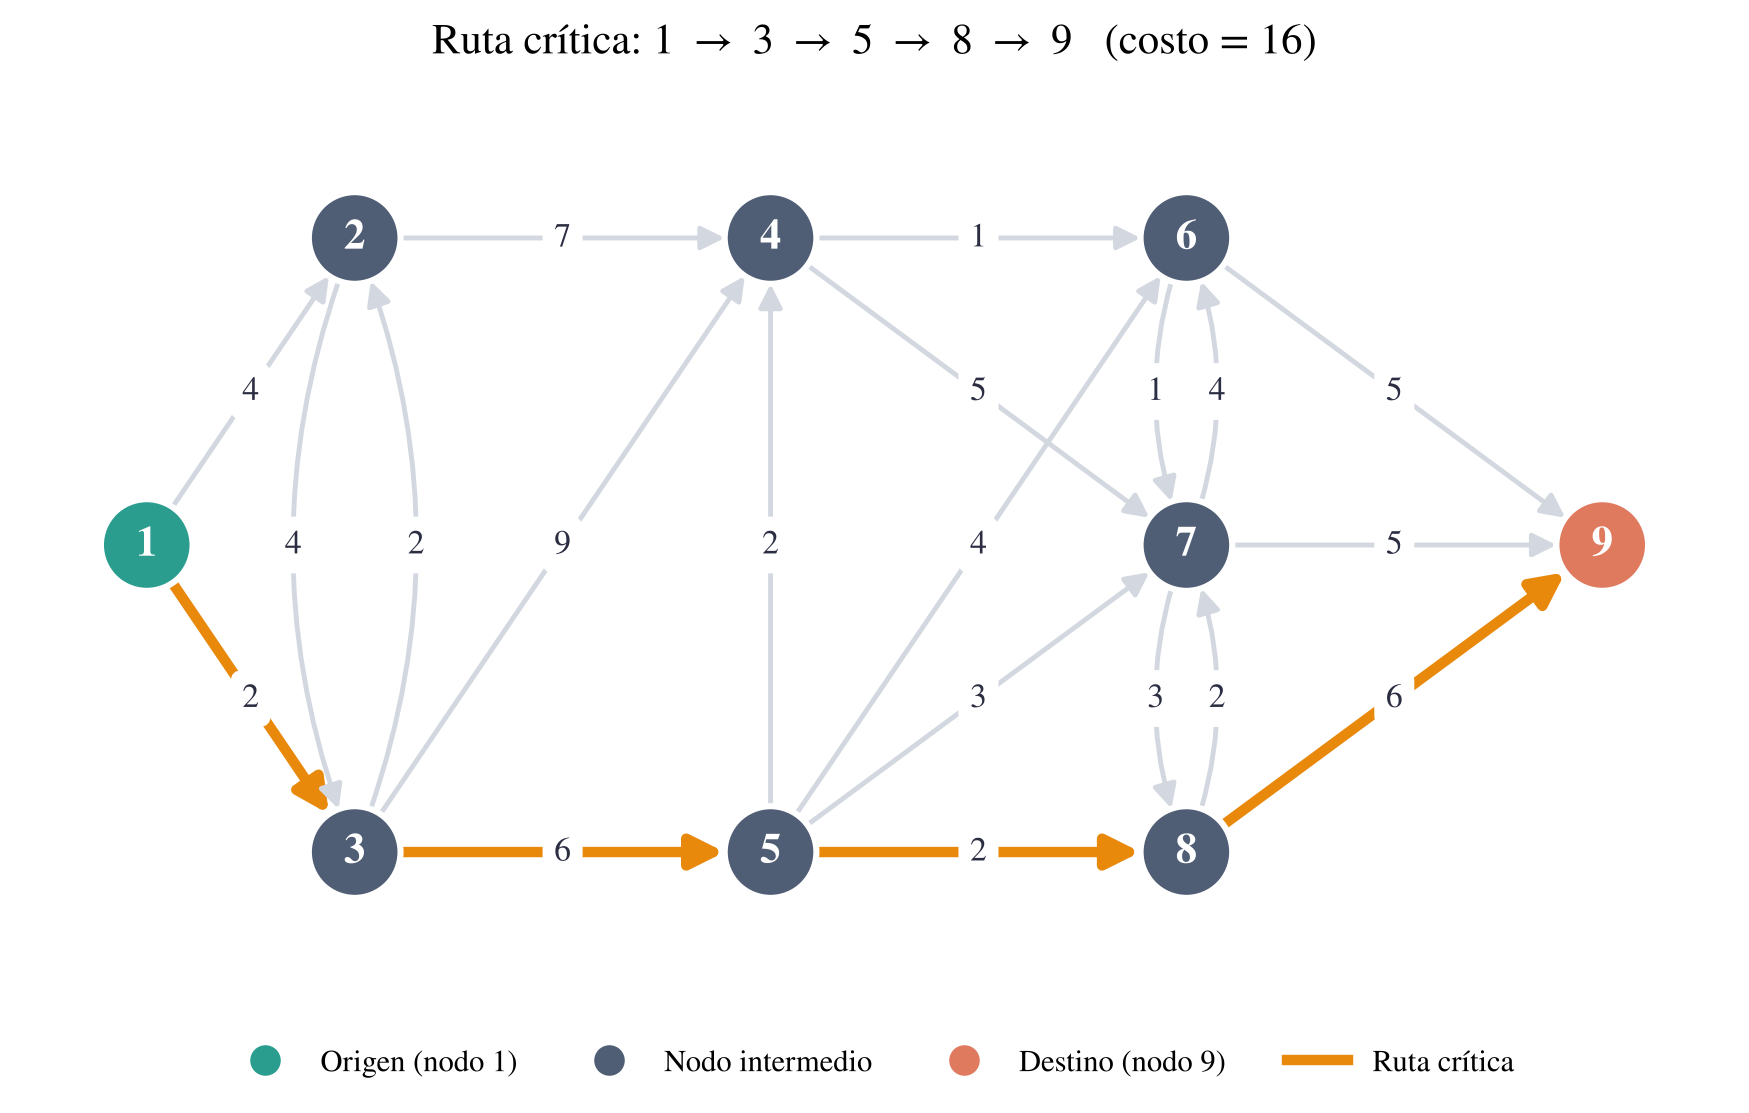

In [12]:
# --- 6.3 Visualización de la ruta crítica -------------------------------------
dibujar_red(ruta_critica,
            f"Ruta crítica: {formato_ruta(ruta_critica)}   (costo = {acumulado})")

In [13]:
# --- 6.4 Resumen final ----------------------------------------------------------
display(Tabla(pd.DataFrame({
    "Concepto": ["Origen", "Destino", "Ruta crítica", "Arcos usados",
                 "Rutas óptimas (Dijkstra)", "Costo Dijkstra", "Costo Gran M",
                 "¿Coinciden?"],
    "Valor": [ORIGEN, DESTINO, formato_ruta(ruta_critica),
              len(ruta_critica) - 1, len(rutas_optimas),
              dist[DESTINO], costo_pl, "Sí" if coinciden else "No"],
}), "Resumen de resultados"))

Concepto,Valor
Origen,1
Destino,9
Ruta crítica,1 → 3 → 5 → 8 → 9
Arcos usados,4
Rutas óptimas (Dijkstra),3
Costo Dijkstra,16
Costo Gran M,16
¿Coinciden?,Sí


## Conclusiones

1. La **ruta de menor costo** entre el nodo 1 y el nodo 9 es **1 → 3 → 5 → 8 → 9**, con un costo total de **16 unidades**.
2. El **algoritmo de Dijkstra** y el **modelo de programación lineal con Gran M** llegan al **mismo valor óptimo**, lo cual valida la formulación.
3. Existen **varias rutas óptimas** con costo 16; por ello un método puede devolver una secuencia distinta sin que exista error (Gran M devolvió 1 → 3 → 5 → 4 → 6 → 9, que también es óptima). La ruta crítica corresponde a la primera ruta óptima encontrada por Dijkstra.
4. La **Gran M** funciona como puente entre el enfoque algorítmico (Dijkstra) y el enfoque algebraico (programación lineal), mostrando la equivalencia entre ambos planteamientos.